In [2]:
%pip install pandas numpy matplotlib wordcloud openpyxl

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.9/554.9 kB 3.3 MB/s  0:00:00
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

In [4]:
# Load Flipkart customer reviews dataset
df = pd.read_csv("Custmor_review_data.csv")

# Display first five records
display(df.head())

# Dataset information
df.info()

# Display column names
print(df.columns.tolist())

,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196029 entries, 0 to 196028
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   product_name   196029 non-null  object
 1   product_price  196029 non-null  object
 2   Rate           196029 non-null  object
 3   Review         171365 non-null  object
 4   Summary        196018 non-null  object
 5   Sentiment      196028 non-null  object
dtypes: object(6)
memory usage: 9.0+ MB
['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']


In [5]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Clean rating column
df["Rate"] = pd.to_numeric(
    df["Rate"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0],
    errors="coerce"
)

# Clean price column
df["product_price"] = pd.to_numeric(
    df["product_price"]
    .astype(str)
    .str.replace(r"[₹,\s]", "", regex=True),
    errors="coerce"
)

# Remove invalid ratings
df.loc[~df["Rate"].between(1, 5), "Rate"] = np.nan

# Remove invalid prices
df.loc[df["product_price"] < 0, "product_price"] = np.nan

# Remove records without product names
df["product_name"] = df["product_name"].astype("string").str.strip()

df = df.dropna(subset=["product_name"])
df = df[df["product_name"].ne("")].copy()

# Check missing values
print("Missing values after cleaning:")
print(df[["Rate", "product_price"]].isnull().sum())

# Display cleaned data
display(df.head())

Missing values after cleaning:
Rate             1
product_price    3
dtype: int64


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,5.0,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,5.0,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,3.0,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,1.0,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,3.0,fair,ok ok product,neutral


In [6]:
# Group by product and calculate mean values
items = df.groupby("product_name").agg(
    mean_rating=("Rate", "mean"),
    mean_price=("product_price", "mean")
).reset_index()

# Round values
items["mean_rating"] = items["mean_rating"].round(2)
items["mean_price"] = items["mean_price"].round(2)

# Display summary
display(items.head(10))

# Count unique products
print("Total unique products:", len(items))

,product_name,mean_rating,mean_price
0,1170BLBR Unique New Day Date Analog Watch F...,3.99,299.0
1,288SDTL TIMEWEAR Silver Pink Dial Stainless St...,4.41,339.0
2,38024PP25 Minimalists Analog Watch For Men,4.89,850.0
3,3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...,3.67,417.0
4,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...,4.75,199.0
5,77085PP03 Volt Analog Watch For Men,4.71,699.0
6,7SEVEN Airtel DTH Remote Airtel Xstream Remote...,4.69,219.0
7,"ADONYX Combo of Knee,Palm, Elbow & Ankle Support",3.80,199.0
8,ADZOY Metal Lazy Stand Bracket for Neck Rest o...,3.52,284.0
9,AGAMI Green 2 Layer Lucky Bamboo plant with Bi...,4.46,279.0


Total unique products: 944


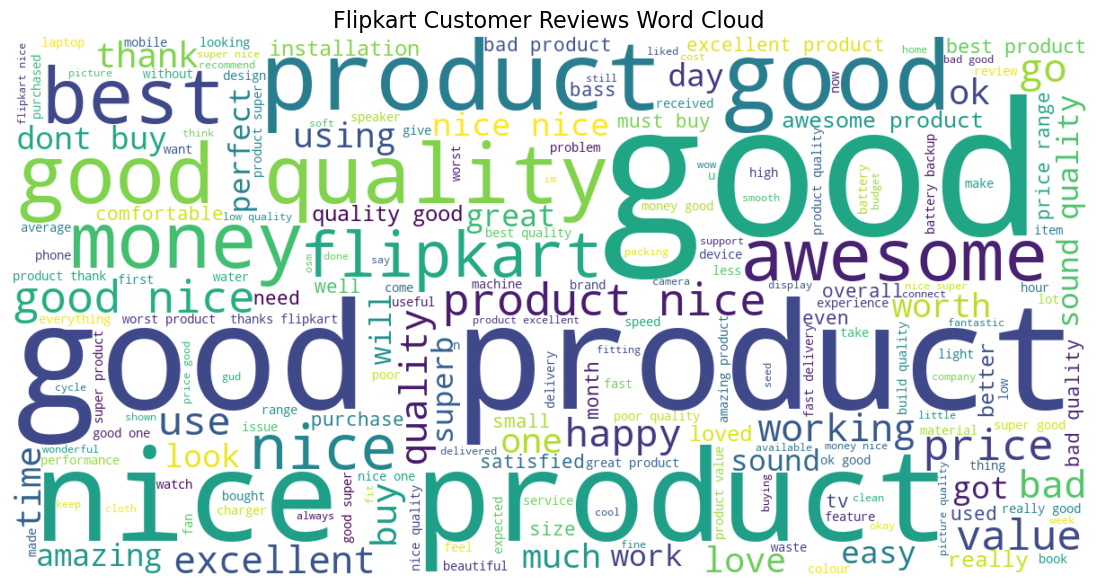

In [7]:
# Combine customer review summaries into one text
text = " ".join(
    df["Summary"].dropna().astype(str)
)

# Generate Word Cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    stopwords=STOPWORDS,
    colormap="viridis",
    max_words=200,
    random_state=42
).generate(text)

# Display Word Cloud
plt.figure(figsize=(14, 7))

plt.imshow(wordcloud, interpolation="bilinear")

plt.axis("off")

plt.title(
    "Flipkart Customer Reviews Word Cloud",
    fontsize=16
)

plt.show()

In [8]:
with pd.ExcelWriter("Flipkart_Customer_Review_Analysis.xlsx") as writer:

    df.to_excel(
        writer,
        sheet_name="Cleaned_Data",
        index=False
    )

    items.to_excel(
        writer,
        sheet_name="Product_Summary",
        index=False
    )

print("Excel file created successfully!")

Excel file created successfully!
